In [13]:

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix,
                             roc_auc_score, RocCurveDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [14]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [15]:
# 3. Data cleaning
print("Duplicate rows:", df.duplicated().sum())
print(df.isnull().sum().sort_values(ascending=False).head(10))

df = df.drop_duplicates()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna(subset=["Churn"])
print("Cleaned shape:", df.shape)
display(df.describe(include="all").T)

Duplicate rows: 0
customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64
Cleaned shape: (7043, 21)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count
Churn,
No,5174
Yes,1869


,proportion
Churn,
No,73.46
Yes,26.54


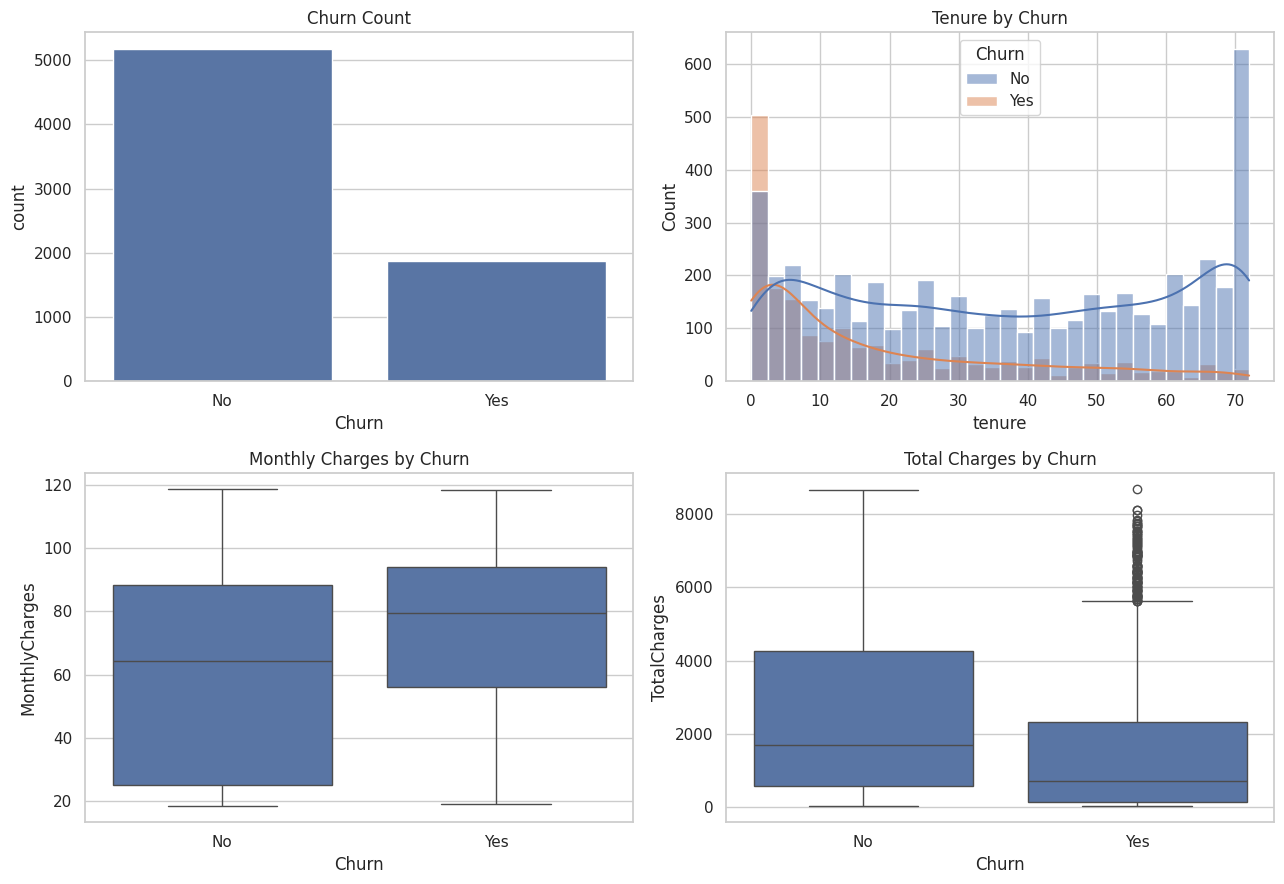

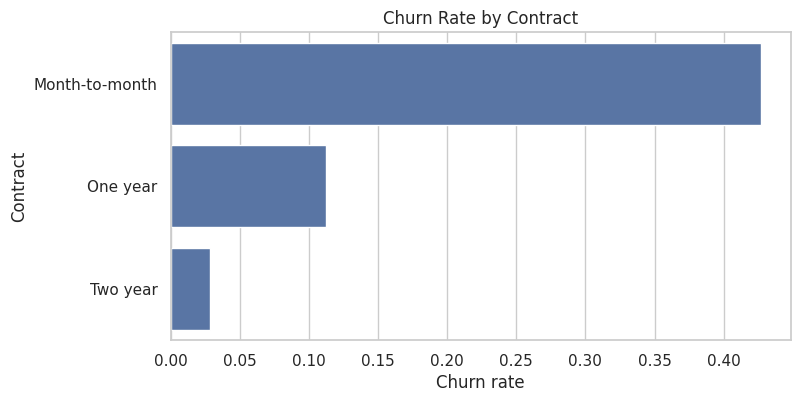

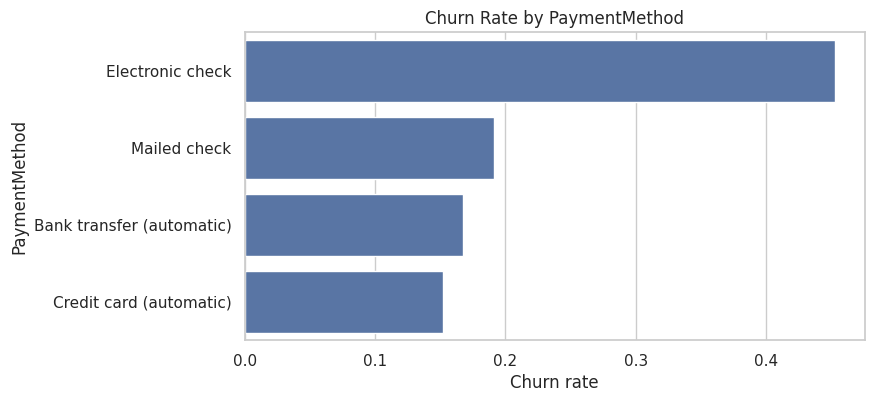

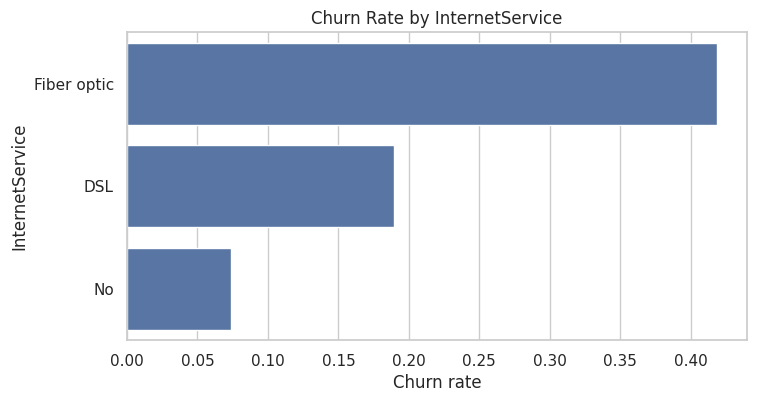

In [16]:
display(df["Churn"].value_counts())
display((df["Churn"].value_counts(normalize=True) * 100).round(2))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="Churn", ax=axes[0, 0])
axes[0, 0].set_title("Churn Count")
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Tenure by Churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 0])
axes[1, 0].set_title("Monthly Charges by Churn")
sns.boxplot(data=df, x="Churn", y="TotalCharges", ax=axes[1, 1])
axes[1, 1].set_title("Total Charges by Churn")
plt.tight_layout()
plt.show()

for col in ["Contract", "PaymentMethod", "InternetService"]:
    rates = df.groupby(col)["Churn"].apply(lambda x: (x == "Yes").mean()).sort_values(ascending=False)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=rates.values, y=rates.index)
    plt.title(f"Churn Rate by {col}")
    plt.xlabel("Churn rate")
    plt.show()

In [17]:
X = df.drop(columns=["Churn", "customerID"], errors="ignore")
y = df["Churn"].map({"No": 0, "Yes": 1})

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

In [18]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                            class_weight="balanced", random_state=RANDOM_STATE)
}

trained_models = {}
scores = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    trained_models[name] = pipe
    scores.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results = pd.DataFrame(scores).sort_values("F1-Score", ascending=False)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,Decision Tree,0.7410,0.5077,0.7914,0.6186,0.8290
2,Random Forest,0.7842,0.5845,0.6471,0.6142,0.8347
0,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413


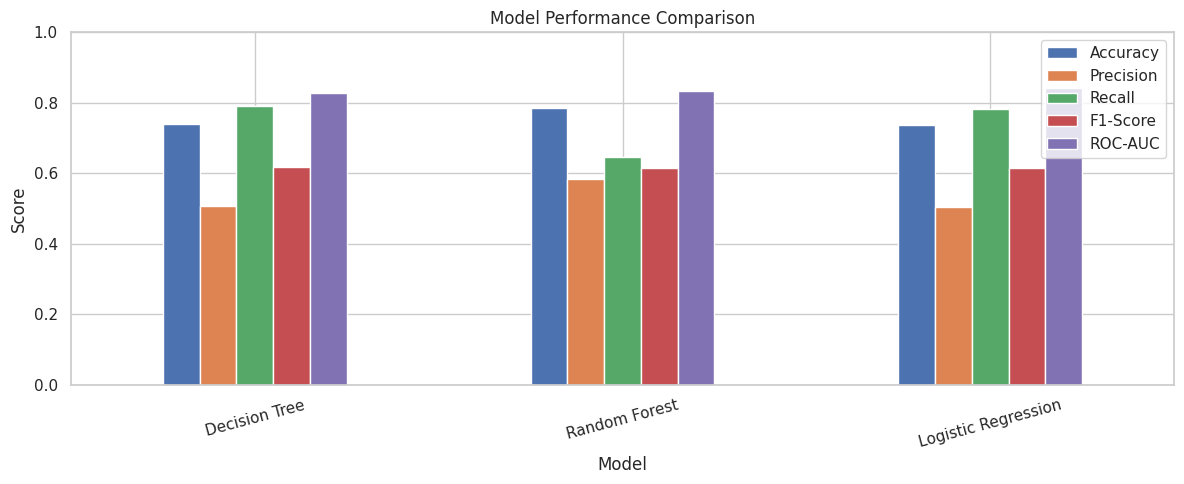

Best model by F1-score: Decision Tree


In [19]:
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

best_name = results.iloc[0]["Model"]
best_model = trained_models[best_name]
print("Best model by F1-score:", best_name)

              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



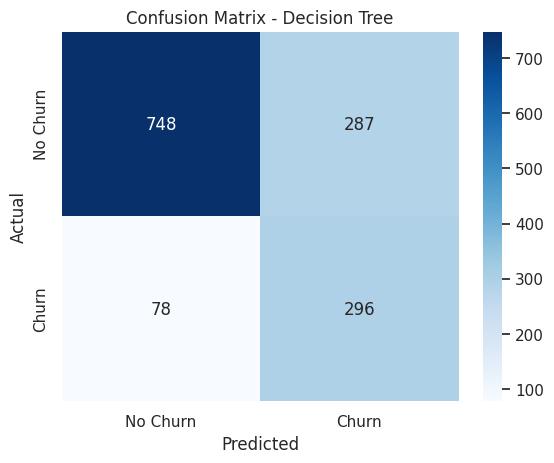

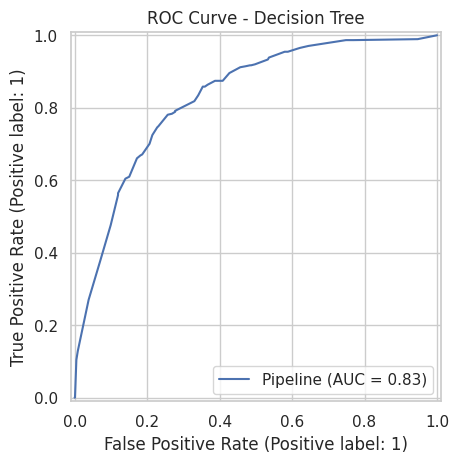

ROC-AUC: 0.829


In [20]:
pred = best_model.predict(X_test)
prob = best_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["No Churn", "Churn"], zero_division=0))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"],
            yticklabels=["No Churn", "Churn"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_name}")
plt.show()

RocCurveDisplay.from_estimator(best_model, X_test, y_test)
plt.title(f"ROC Curve - {best_name}")
plt.show()
print("ROC-AUC:", round(roc_auc_score(y_test, prob), 4))

,Feature,Importance
36,cat__Contract_Month-to-month,0.560884
1,num__tenure,0.104477
16,cat__InternetService_Fiber optic,0.099554
2,num__MonthlyCharges,0.074523
3,num__TotalCharges,0.030015
38,cat__Contract_Two year,0.020974
43,cat__PaymentMethod_Electronic check,0.019974
27,cat__TechSupport_No,0.017933
33,cat__StreamingMovies_No,0.015087
18,cat__OnlineSecurity_No,0.014890


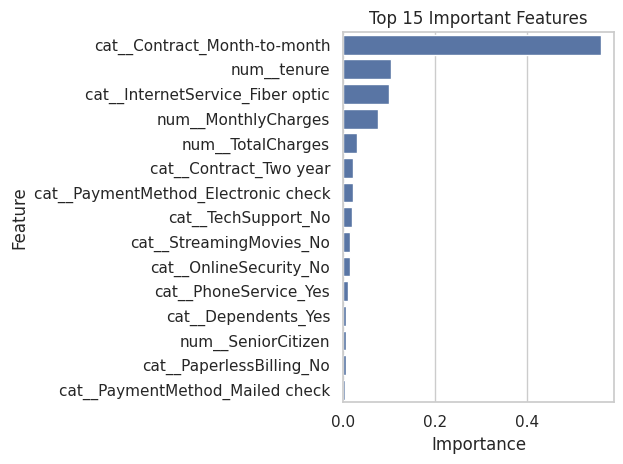

In [21]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_model = best_model.named_steps["model"]
feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_model, "feature_importances_"):
    importances = fitted_model.feature_importances_
elif hasattr(fitted_model, "coef_"):
    importances = np.abs(fitted_model.coef_).mean(axis=0)
else:
    importances = None

if importances is not None:
    feature_importance = pd.DataFrame({
        "Feature": feature_names, "Importance": importances
    }).sort_values("Importance", ascending=False)
    display(feature_importance.head(15))
    sns.barplot(data=feature_importance.head(15), x="Importance", y="Feature")
    plt.title("Top 15 Important Features")
    plt.tight_layout()
    plt.show()

In [22]:
def predict_churn(customer_details):
    customer = pd.DataFrame([customer_details]).reindex(columns=X.columns)
    churn_probability = float(best_model.predict_proba(customer)[0, 1])
    risk = "High" if churn_probability >= 0.70 else "Medium" if churn_probability >= 0.40 else "Low"
    return {
        "Predicted Churn": "Yes" if churn_probability >= 0.50 else "No",
        "Churn Probability": round(churn_probability, 4),
        "Risk Level": risk
    }

sample_customer = X_test.iloc[0].to_dict()
print(predict_churn(sample_customer))

{'Predicted Churn': 'No', 'Churn Probability': 0.0, 'Risk Level': 'Low'}


In [23]:
def retention_recommendations(customer):
    actions = []
    if customer.get("Contract") == "Month-to-month":
        actions.append("Offer an incentive to move to a longer-term contract.")
    if customer.get("PaymentMethod") == "Electronic check":
        actions.append("Offer assistance setting up automatic payment.")
    if customer.get("TechSupport") == "No":
        actions.append("Promote technical support options.")
    if customer.get("OnlineSecurity") == "No":
        actions.append("Explain available online security services.")
    if customer.get("tenure", 0) < 12:
        actions.append("Provide an onboarding check-in for this newer customer.")
    if not actions:
        actions.append("Offer a personalized loyalty check-in.")
    return actions

for action in retention_recommendations(sample_customer):
    print("-", action)

- Offer a personalized loyalty check-in.


In [24]:
joblib.dump(best_model, "customer_churn_model.pkl")
results.to_csv("model_comparison.csv", index=False)
df.to_csv("cleaned_telco_churn.csv", index=False)
if "feature_importance" in globals():
    feature_importance.to_csv("feature_importance.csv", index=False)

print("Saved model and output CSV files.")

Saved model and output CSV files.
